# Which window for Σ̂? Risk-model test on rebuilt history (K = 30, τ = 10, in-sample)

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from sklearn.covariance import LedoitWolf
from eda_data import *
from src.config import CENTROIDS_NPZ, CHARS_CLEAN_PARQUET, MIN_HISTORY_MONTHS, TAU, TARGET_COL, feature_cols
from src.factors.build_panel import load_panel

factor_returns, _ = load_panel()
F = factor_returns.drop("DATE").to_numpy()
dates = factor_returns["DATE"].to_numpy()
C = np.load(CENTROIDS_NPZ)["centroids"]
df = pl.read_parquet(CHARS_CLEAN_PARQUET).filter(pl.col("DATE") <= IS_END_DATE)
features = feature_cols(df.columns)
groups = [g for _, g in df.group_by("DATE", maintain_order=True)]
Xn = [g.select(features).to_numpy() for g in groups]
Xn = [X / np.linalg.norm(X, axis=1, keepdims=True) for X in Xn]
R = [g[TARGET_COL].to_numpy() for g in groups]
T, K = F.shape

def factor_returns_with(centroids, X, r, tau=TAU):
    S = X @ centroids.T
    P = np.exp(tau * (S - S.max(axis=1, keepdims=True))); P /= P.sum(axis=1, keepdims=True)
    W = P - P.mean(axis=0)
    return (W / np.abs(W).sum(axis=0)).T @ r

rebuilt = {t: np.array([factor_returns_with(C[t], Xn[s], R[s]) for s in range(t)]) for t in range(MIN_HISTORY_MONTHS, T)}
print(T, "months,", K, "factors")

191 months, 30 factors


## Covariance estimators (all Ledoit-Wolf shrunk)

In [2]:
HALF_LIFE = 12
def sigma_hat(hist, window):
    if window == "ewma":
        w = 0.5 ** (np.arange(len(hist))[::-1] / HALF_LIFE); w /= w.sum()
        centred = hist - w @ hist
        return LedoitWolf(assume_centered=True).fit(centred * np.sqrt(w * len(hist))[:, None]).covariance_
    data = hist if window == "expanding" else hist[-window:]
    return LedoitWolf(assume_centered=False).fit(data).covariance_

WINDOWS = [12, 24, 36, 60, "expanding", "ewma"]
LABELS = ["12m", "24m", "36m", "60m", "exp.", f"EWMA hl={HALF_LIFE}m"]
rng = np.random.default_rng(0)
RANDOM = rng.normal(size=(200, K)); RANDOM /= np.abs(RANDOM).sum(axis=1, keepdims=True)
rows = []
for window, label in zip(WINDOWS, LABELS):
    for t in range(MIN_HISTORY_MONTHS, T):
        S = sigma_hat(rebuilt[t], window)
        rows.append({"window": label, "DATE": int(dates[t]),
                     **{f"z_{k}": F[t, k] / np.sqrt(S[k, k]) for k in range(K)},
                     **{f"r_{j}": (RANDOM[j] @ F[t]) / np.sqrt(RANDOM[j] @ S @ RANDOM[j]) for j in range(len(RANDOM))}})
res = pl.DataFrame(rows)

## Realised ÷ predicted risk (std of return / predicted vol; 1 = accurate, above 1 = risk underestimated)

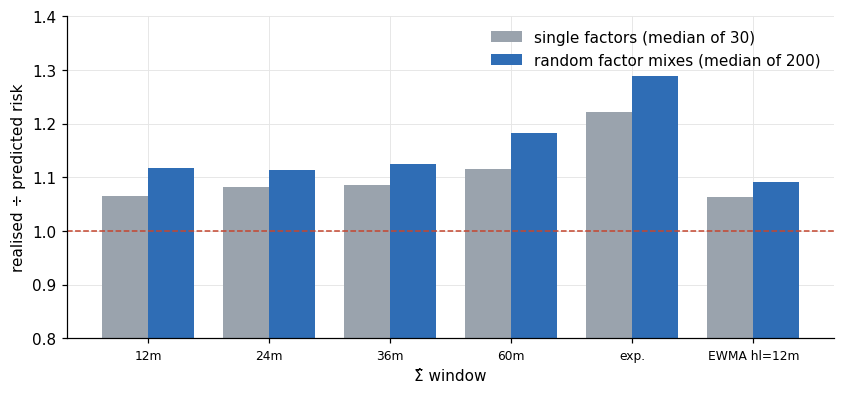

window,single_factors_median,random_factor_mixes_median
str,f64,f64
"""12m""",1.0653,1.1178
"""24m""",1.0818,1.1140
"""36m""",1.0861,1.1242
"""60m""",1.1151,1.1816
"""exp.""",1.2225,1.2890
"""EWMA hl=12m""",1.0633,1.0910


In [3]:
def summarise(frame):
    out = []
    for label in LABELS:
        s = frame.filter(pl.col("window") == label)
        z = s.select([f"z_{k}" for k in range(K)]).to_numpy()
        rz = s.select([f"r_{j}" for j in range(len(RANDOM))]).to_numpy()
        out.append({"window": label, "single_factors_median": float(np.median(z.std(axis=0, ddof=1))),
                    "random_factor_mixes_median": float(np.median(rz.std(axis=0, ddof=1)))})
    return pl.DataFrame(out)
summary = summarise(res)
x = np.arange(len(LABELS)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(x - w / 2, summary["single_factors_median"], w, color=GREY, label="single factors (median of 30)")
ax.bar(x + w / 2, summary["random_factor_mixes_median"], w, color=BLUE, label="random factor mixes (median of 200)")
ax.axhline(1, color="#c4462f", lw=1, ls="--"); ax.set_ylim(0.8, 1.4)
ax.set_xticks(x, LABELS, fontsize=8); ax.set_xlabel("Σ̂ window"); ax.set_ylabel("realised ÷ predicted risk")
ax.legend(frameon=False); plt.show()
summary

## Stability: 1993–1999 vs 2000–2005 (random factor mixes)

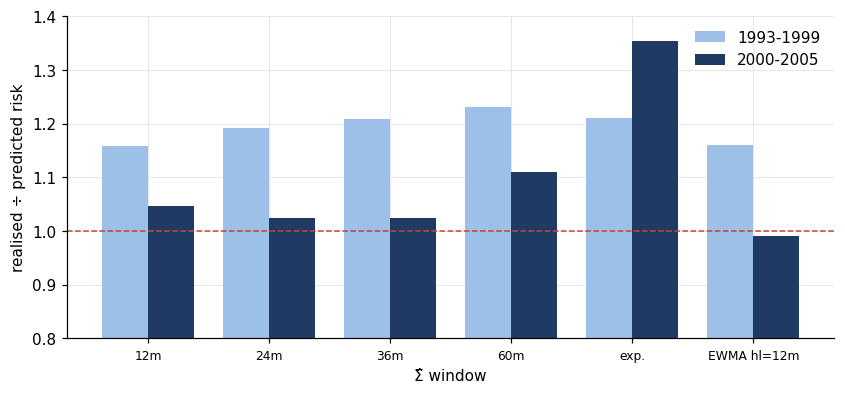

window,single_factors_median,random_factor_mixes_median,period
str,f64,f64,str
"""12m""",1.0592,1.1592,"""1993-1999"""
"""24m""",1.1216,1.1912,"""1993-1999"""
"""36m""",1.1363,1.2080,"""1993-1999"""
"""60m""",1.1504,1.2309,"""1993-1999"""
"""exp.""",1.1055,1.2107,"""1993-1999"""
"""EWMA hl=12m""",1.0569,1.1594,"""1993-1999"""
"""12m""",1.0128,1.0470,"""2000-2005"""
"""24m""",0.9777,1.0239,"""2000-2005"""
"""36m""",0.9799,1.0245,"""2000-2005"""


In [4]:
halves = pl.concat([summarise(res.filter(pl.col("DATE") < 20000101)).with_columns(pl.lit("1993-1999").alias("period")),
                    summarise(res.filter(pl.col("DATE") >= 20000101)).with_columns(pl.lit("2000-2005").alias("period"))])
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (period, color) in enumerate([("1993-1999", "#9cc0e8"), ("2000-2005", "#1f3b63")]):
    s = halves.filter(pl.col("period") == period)
    ax.bar(x + (i - 0.5) * w, s["random_factor_mixes_median"], w, color=color, label=period)
ax.axhline(1, color="#c4462f", lw=1, ls="--"); ax.set_ylim(0.8, 1.4)
ax.set_xticks(x, LABELS, fontsize=8); ax.set_xlabel("Σ̂ window"); ax.set_ylabel("realised ÷ predicted risk")
ax.legend(frameon=False); plt.show()
halves.sort("period")